In [1]:
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import cv2

sys.path.append("..")
from tflite_inference import TFLiteInferer

%load_ext autoreload
%autoreload 2

2025-07-31 19:17:53.032161: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-07-31 19:17:53.048340: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-07-31 19:17:53.053346: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-07-31 19:17:53.065722: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-07-31 19:17:53.952425: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [2]:
def draw_output(img, output):
    tmp = img.copy()
    for box in output:
        x1, y1, w, h, conf, _, x, y = box
        x2 = x1 + w
        y2 = y1 + h
        cv2.rectangle(tmp, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.circle(tmp, (int(x), int(y)), 9, (0, 255, 0), -1)
        cv2.putText(tmp, f"{conf:.2f}", (int(x1), int(y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    plt.imshow(tmp)

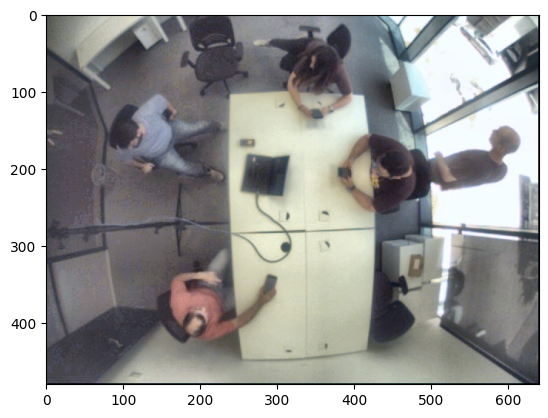

In [3]:
img_pth = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_5_margin_15_bg_wb_alif_clahe/images/val/4.2_batch2____4.2_H_cam_262_spacesMR_201.jpg"
img = cv2.imread(img_pth)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [4]:
base_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_saved_model/head_float32.tflite",
    conf_th=0.20
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [5]:
output = base_model.infer(img)
output

array([[ 79.57479858, 104.09059906, 156.44857788, 118.73403168,
          0.89444411,   0.        , 163.41456604, 168.974823  ],
       [377.2996521 , 155.93057251, 104.47747803, 103.57861328,
          0.89444411,   0.        , 426.24371338, 209.07284546],
       [304.96200562,  37.67615891,  98.28189087,  99.30024719,
          0.84678036,   0.        , 355.85296631, 101.56026459],
       [478.17895508, 140.92236328, 141.84381104,  90.32310486,
          0.84678036,   0.        , 492.78146362, 204.3894043 ],
       [157.62878418, 295.16271973, 141.60894775, 130.95065308,
          0.84678036,   0.        , 226.14569092, 355.4145813 ]])

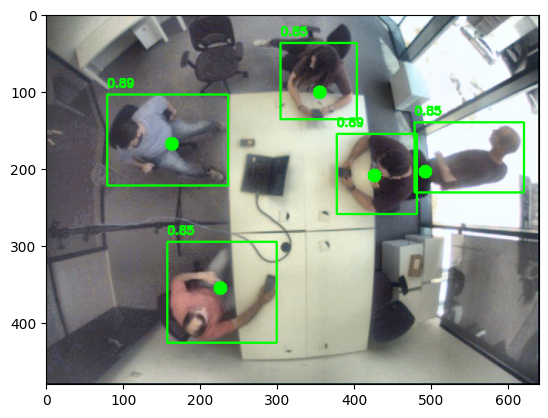

In [6]:
draw_output(img, output)

In [13]:
sep_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model/head_float32.tflite",
    conf_th=0.20,
    separated_head=True
)

In [14]:
output = sep_model.infer(img)
output

array([[ 79.57479858, 104.09059906, 156.44857788, 118.73403168,
          0.89444411,   0.        , 163.41456604, 168.974823  ],
       [377.2996521 , 155.93057251, 104.47747803, 103.57861328,
          0.89444411,   0.        , 426.24371338, 209.07284546],
       [304.96200562,  37.67615891,  98.28189087,  99.30024719,
          0.84678036,   0.        , 355.85296631, 101.56026459],
       [478.17895508, 140.92236328, 141.84381104,  90.32310486,
          0.84678036,   0.        , 492.78146362, 204.3894043 ],
       [157.62878418, 295.16271973, 141.60894775, 130.95065308,
          0.84678036,   0.        , 226.14569092, 355.4145813 ]])

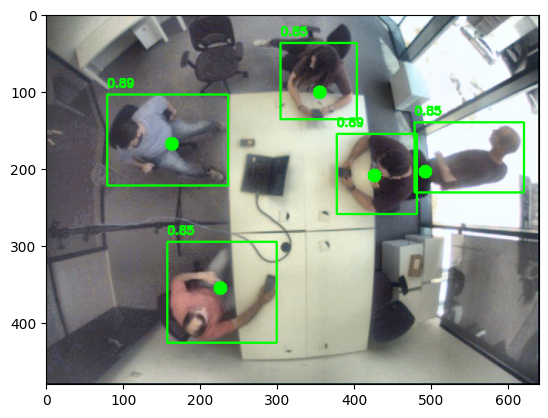

In [15]:
draw_output(img, output)

In [16]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model/head_full_integer_quant.tflite",
    conf_th=0.20,
    separated_head=True,
    head_int8=True,
    idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [18]:
output = sep_quant_model.infer(img, quantized_output=False)
output

array([[ 1.48437500e-01, -4.88870453e+02, -4.88870453e+02,
         9.77740906e+02,  4.88870453e+02,  0.00000000e+00,
        -3.28459839e+02, -3.28459839e+02]])

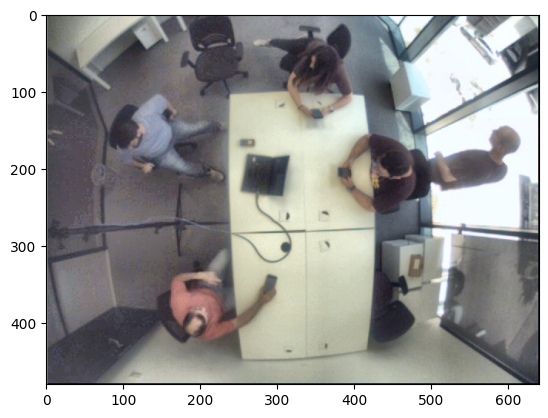

In [19]:
draw_output(img, output)